<a href="https://colab.research.google.com/github/Almi25/PCD_Almi/blob/main/PCD_6_Almi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ukuran citra asli : (1200, 675, 3)
Citra Asli                         : (1200, 675, 3)
Translasi (tx=168, ty=300)         : (1200, 675, 3)
Scaling 0,5x                       : (600, 338, 3)
Scaling 2x                         : (2400, 1350, 3)
Rotasi 45°                         : (1326, 1326, 3)
Rotasi 90°                         : (675, 1200, 3)
Rotasi 180°                        : (1200, 675, 3)
Horizontal Flip                    : (1200, 675, 3)
Vertical Flip                      : (1200, 675, 3)


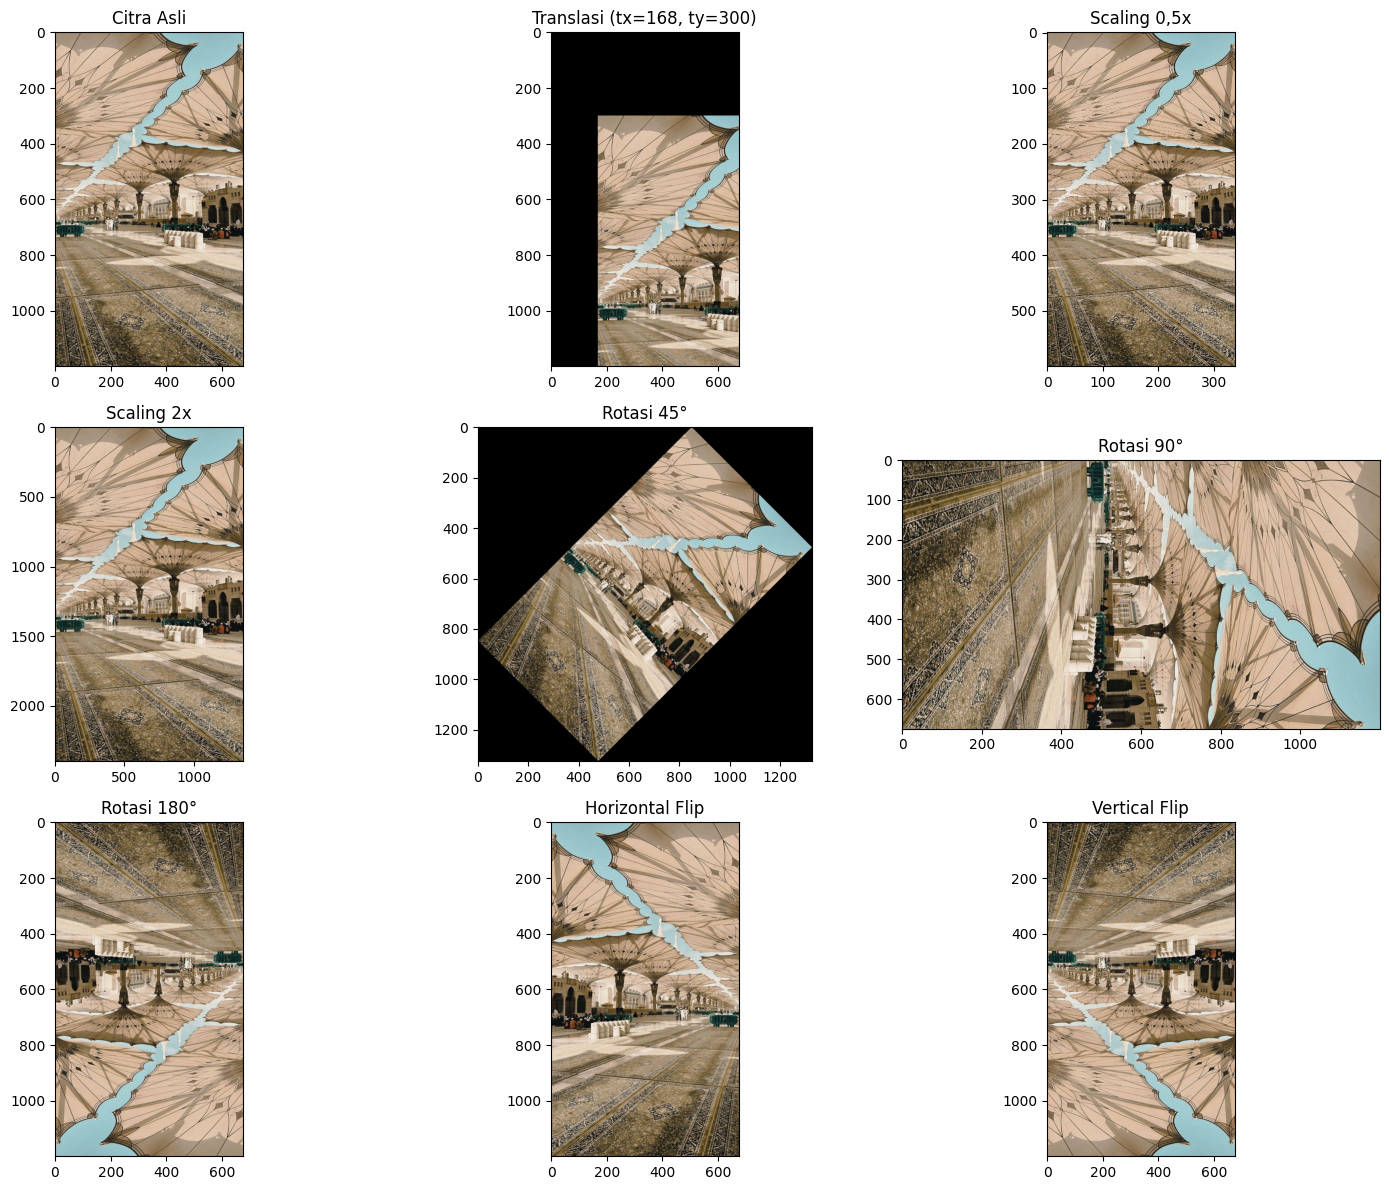

In [1]:
import imageio.v2 as imageio
import numpy as np
import matplotlib.pyplot as plt

nama_file = "/content/Masjid Nabawi.jpg"

#1. membaca citra
img = imageio.imread(nama_file)
if img.ndim == 2:
    img = np.stack([img]*3, axis=-1)
img = img[:, :, :3]
tinggi, lebar = img.shape[:2]
print("Ukuran citra asli :", img.shape)

#2. fungsi dasar: transformasi affine (inverse mapping)
def transform_affine(img, M, ukuran_keluar):
    """M = matriks 3x3 (koordinat homogen), dari citra asli ke citra hasil."""
    h_out, w_out = ukuran_keluar
    hasil = np.zeros((h_out, w_out, img.shape[2]), dtype=img.dtype)
    M_inv = np.linalg.inv(M)
    yy, xx = np.indices((h_out, w_out))
    koord = np.stack([xx.ravel(), yy.ravel(), np.ones(xx.size)])
    src = M_inv @ koord
    xs = np.rint(src[0]).astype(int)
    ys = np.rint(src[1]).astype(int)
    valid = (xs >= 0) & (xs < img.shape[1]) & (ys >= 0) & (ys < img.shape[0])
    hasil[yy.ravel()[valid], xx.ravel()[valid]] = img[ys[valid], xs[valid]]
    return hasil

#3. translation
def translasi(img, tx, ty):
    M = np.array([[1, 0, tx],
                  [0, 1, ty],
                  [0, 0, 1]], dtype=float)
    return transform_affine(img, M, img.shape[:2])

#4. scaling
def skala(img, faktor):
    h, w = img.shape[:2]
    M = np.array([[faktor, 0, 0],
                  [0, faktor, 0],
                  [0, 0, 1]], dtype=float)
    return transform_affine(img, M, (int(round(h*faktor)), int(round(w*faktor))))

#5. rotation (searah jarum jam, terhadap pusat citra)
def rotasi(img, sudut):
    h, w = img.shape[:2]
    a = np.deg2rad(sudut)
    c, s = np.cos(a), np.sin(a)
    w_out = int(np.ceil(round(abs(w*c) + abs(h*s), 6)))
    h_out = int(np.ceil(round(abs(w*s) + abs(h*c), 6)))
    T1 = np.array([[1, 0, -(w-1)/2], [0, 1, -(h-1)/2], [0, 0, 1]])
    R  = np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])
    T2 = np.array([[1, 0, (w_out-1)/2], [0, 1, (h_out-1)/2], [0, 0, 1]])
    return transform_affine(img, T2 @ R @ T1, (h_out, w_out))

#6. flip
def flip_horizontal(img):
    h, w = img.shape[:2]
    M = np.array([[-1, 0, w-1],
                  [0, 1, 0],
                  [0, 0, 1]], dtype=float)
    return transform_affine(img, M, (h, w))

def flip_vertikal(img):
    h, w = img.shape[:2]
    M = np.array([[1, 0, 0],
                  [0, -1, h-1],
                  [0, 0, 1]], dtype=float)
    return transform_affine(img, M, (h, w))

#7. jalankan semua transformasi
hasil = [
    ("Citra Asli", img),
    (f"Translasi (tx={lebar//4}, ty={tinggi//4})", translasi(img, lebar//4, tinggi//4)),
    ("Scaling 0,5x", skala(img, 0.5)),
    ("Scaling 2x", skala(img, 2)),
    ("Rotasi 45°", rotasi(img, 45)),
    ("Rotasi 90°", rotasi(img, 90)),
    ("Rotasi 180°", rotasi(img, 180)),
    ("Horizontal Flip", flip_horizontal(img)),
    ("Vertical Flip", flip_vertikal(img)),
]

for nama, g in hasil:
    print(f"{nama:35s}: {g.shape}")

#8. tampilkan citra asli dan semua hasil
plt.figure(figsize=(15, 12))
for i, (nama, g) in enumerate(hasil, 1):
    plt.subplot(3, 3, i)
    plt.imshow(g)
    plt.title(nama)
plt.tight_layout()
plt.show()